# Kunci Lab 4: Model Kategorikal



**Pengayaan pilihan:** keputusan kredit berdasarkan biaya (30 sampai 40 menit). Waktu ini di luar durasi materi inti.

## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita menyesuaikan model dengan jenis target. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan peluang, kelas, urutan kategori, dan hitungan.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

# Siapkan alat untuk contoh model khusus; jalankan apa adanya.
import sys
import tempfile
from urllib.request import urlretrieve

folder_alat = tempfile.mkdtemp(prefix="alat_ekonometrika_")
urlretrieve(
    "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/alat_bantu/metode_lanjutan.py",
    folder_alat + "/metode_lanjutan.py",
)
sys.path.insert(0, folder_alat)

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import PoissonRegressor
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Latihan 1: perfect separation pada data kelulusan



<!-- kamus_variabel:logit_probit_2.csv -->

### Kenali data: Kelulusan tepat waktu

**Data:** `data/logit_probit_2.csv`. **Satu baris:** satu mahasiswa.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `LULUS_TEPAT` | Apakah mahasiswa menyelesaikan studi tepat waktu. | 1 = tepat waktu; 0 = tidak tepat waktu | Y: target |
| `IPK_SEM2` | Indeks Prestasi Kumulatif sampai semester 2. | Poin IPK | X: penjelas |
| `SKS_LULUS_SEM2` | Beban studi yang telah diselesaikan sampai semester 2; SKS = Satuan Kredit Semester. | SKS | X: penjelas |
| `KEAKTIFAN_ORG` | Keaktifan mahasiswa dalam organisasi. | 1 = aktif; 0 = tidak aktif | X: penjelas |
| `BEASISWA` | Status penerimaan beasiswa. | 1 = penerima; 0 = bukan penerima | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
lulus = pd.read_csv(URL_DATA + "logit_probit_2.csv")

lulus.head()

,LULUS_TEPAT,IPK_SEM2,SKS_LULUS_SEM2,KEAKTIFAN_ORG,BEASISWA
0,1,3.85,44,0,1
1,0,2.75,36,1,0
2,1,3.50,42,1,1
3,0,2.90,38,0,0
4,1,3.95,44,1,1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
formula = "LULUS_TEPAT ~ IPK_SEM2 + SKS_LULUS_SEM2 + KEAKTIFAN_ORG + BEASISWA"

from metode_lanjutan import coba_logit

print("Koefisien MLE polos (dapat gagal karena separation):")
print(coba_logit(formula, lulus))

sampel_m2 = lulus[
    ["LULUS_TEPAT", "IPK_SEM2", "SKS_LULUS_SEM2", "KEAKTIFAN_ORG", "BEASISWA"]
].dropna()
X_m2 = sampel_m2[["IPK_SEM2", "SKS_LULUS_SEM2", "KEAKTIFAN_ORG", "BEASISWA"]]
y_m2 = sampel_m2["LULUS_TEPAT"]

Koefisien MLE polos (dapat gagal karena separation):
MLE konvergen: False
Koefisien pada data terpisah tidak layak dipakai untuk inferensi.
Intercept         -81.769
IPK_SEM2          218.173
SKS_LULUS_SEM2    -15.655
KEAKTIFAN_ORG       2.165
BEASISWA           -8.343
dtype: float64


C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [5]:
m2 = LogisticRegression(
    penalty="l1", C=2.0, solver="liblinear", max_iter=5000, tol=1e-9
)
m2.fit(X_m2, y_m2)

koefisien_m2 = pd.Series(m2.coef_[0], index=X_m2.columns)
koefisien_m2.loc["Intercept"] = m2.intercept_[0]
print("\nKoefisien setelah regularisasi:")
print(koefisien_m2.round(3))



Koefisien setelah regularisasi:
IPK_SEM2          15.097
SKS_LULUS_SEM2    -1.235
KEAKTIFAN_ORG     -0.121
BEASISWA           0.000
Intercept          0.000
dtype: float64


### Lihat pemisahan kelas pada contoh kelulusan

Regularisasi L1 mempertahankan koefisien berhingga, tetapi tidak menghilangkan kebutuhan memeriksa data.

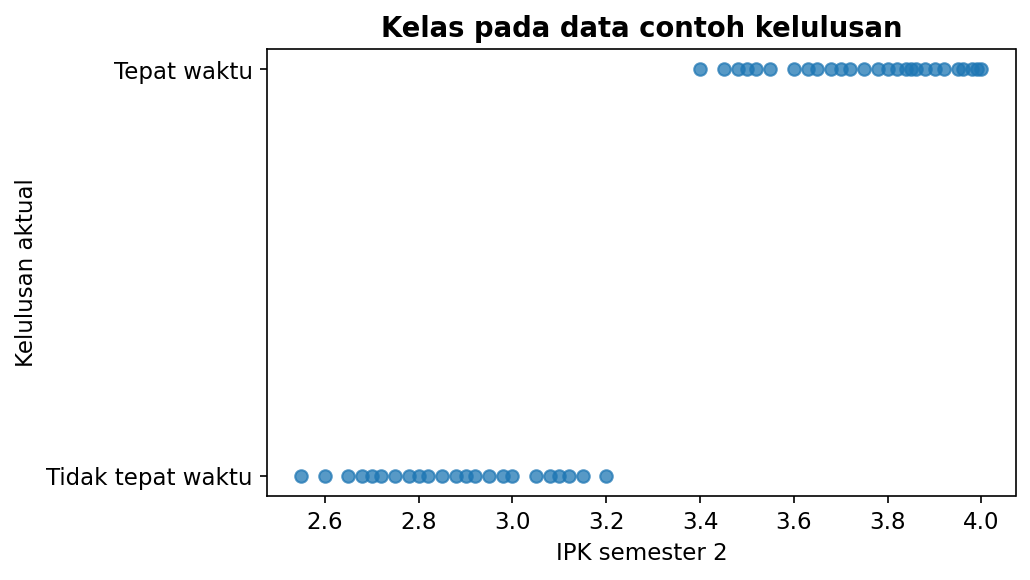

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(lulus["IPK_SEM2"], lulus["LULUS_TEPAT"], alpha=0.75)
ax.set_yticks([0, 1], ["Tidak tepat waktu", "Tepat waktu"])
ax.set_xlabel("IPK semester 2")
ax.set_ylabel("Kelulusan aktual")
ax.set_title("Kelas pada data contoh kelulusan")
plt.tight_layout()
plt.show()

**Cara membaca:** Cocokkan pola kelas dengan peringatan separation yang dibahas. Grafik satu fitur hanya petunjuk; pemisahan perlu diperiksa pada kombinasi fitur model.

Kesimpulan: kombinasi nilai X memprediksi kelulusan secara sempurna
(perfect separation), sehingga likelihood maksimum tidak punya solusi
berhingga dan koefisien meledak. Regularisasi menstabilkannya: IPK
tetap positif (pengaruh terbesar), SKS dan keaktifan organisasi negatif
setelah IPK dikontrol. Untuk laporan, sebutkan keterbatasan estimator
ini karena p-value tidak tersedia.



## Latihan 2: model ordinal (multi-ordinal-1)



<!-- kamus_variabel:multi_ordinal_1.csv -->

### Kenali data: Kepuasan layanan bank

**Data:** `data/multi_ordinal_1.csv`. **Satu baris:** satu responden pengguna layanan bank.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Kepuasan` | Kategori kepuasan terhadap layanan, berurutan dari rendah ke tinggi. | 1 = sangat tidak puas; 2 = netral; 3 = puas | Y: target |
| `Kecepatan` | Lama menunggu pelayanan. Angka lebih besar berarti menunggu lebih lama. | Menit | X: penjelas |
| `Staf_Ramah` | Penilaian keramahan staf. | Skor 1 sampai 10 | X: penjelas |
| `Digital_App` | Frekuensi penggunaan aplikasi digital bank yang dibuat sebagai indikator. | 1 = sering memakai; 0 = jarang/tidak | X: penjelas |

Nama Kecepatan pada CSV berarti waktu tunggu, bukan skor kecepatan. Di contoh utama namanya diperjelas menjadi waktu_tunggu.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [7]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

kepuasan = pd.read_csv(URL_DATA + "multi_ordinal_1.csv")

kepuasan.head()

,Kepuasan,Kecepatan,Staf_Ramah,Digital_App
0,2,8,7,1
1,1,12,4,0
2,3,4,9,1
3,2,7,6,1
4,1,10,5,0


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [8]:
model_ord = OrderedModel(
    kepuasan["Kepuasan"],
    kepuasan[["Kecepatan", "Staf_Ramah", "Digital_App"]],
    distr="logit",
).fit(method="bfgs", disp=False)
print(model_ord.params.round(3))

Kecepatan     -32.701
Staf_Ramah     50.018
Digital_App    18.229
1/2            -5.066
2/3             5.625
dtype: float64


### Bandingkan jumlah responden tiap tingkat kepuasan

Kode kepuasan mempunyai urutan rendah, sedang, dan tinggi.

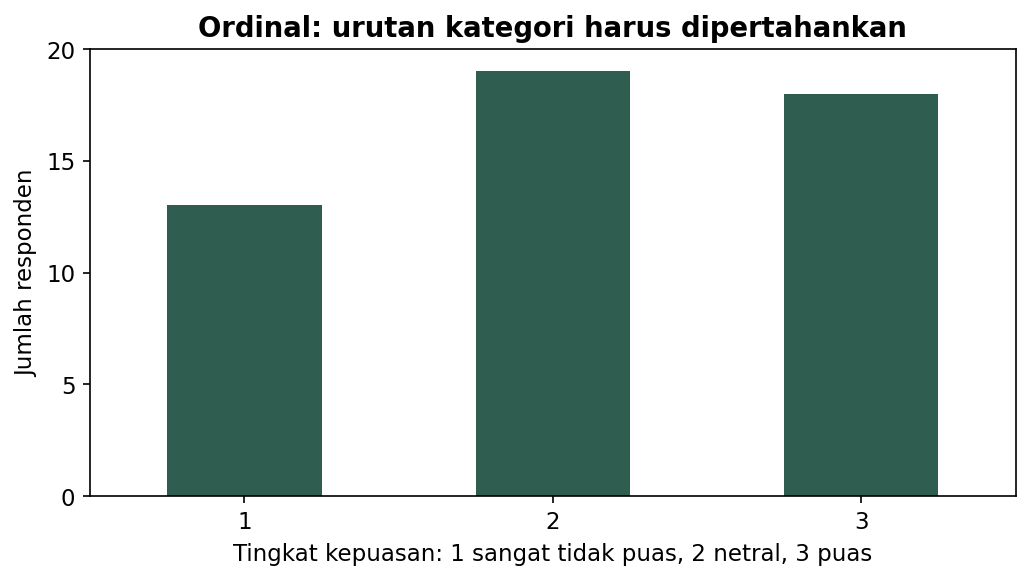

In [9]:
jumlah_kategori = kepuasan["Kepuasan"].value_counts().sort_index()
ax = jumlah_kategori.plot(kind="bar", color="#2F5D50", figsize=(7, 4), rot=0)
ax.set_xlabel("Tingkat kepuasan: 1 sangat tidak puas, 2 netral, 3 puas")
ax.set_ylabel("Jumlah responden")
ax.set_title("Ordinal: urutan kategori harus dipertahankan")
ax.set_yticks([0, 5, 10, 15, 20])
plt.tight_layout()
plt.show()

**Cara membaca:** Urutan kategori dipertahankan. Perbedaan kode tidak menyatakan jarak kepuasan yang pasti sama; karena itu contoh menggunakan model ordinal.

Kesimpulan (baca tanda, bukan besaran):

- Kecepatan (waktu tunggu, menit) negatif: makin lama menunggu, makin
  tidak puas.
- Staf_Ramah positif: makin ramah, makin puas.
- Digital_App positif: yang sering memakai aplikasi cenderung lebih puas.

Koefisien absolutnya puluhan karena data simulasi nyaris terpisah
sempurna. Jangan mengutip besarannya di laporan dengan data seperti ini.



## Latihan 3: Poisson (poisson-1)



<!-- kamus_variabel:poisson_data_1_klaim.csv -->

### Kenali data: Klaim asuransi mobil

**Data:** `data/poisson_data_1_klaim.csv`. **Satu baris:** satu pengemudi/pemegang polis yang diamati selama satu tahun.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `JML_KLAIM` | Jumlah pengajuan klaim asuransi dalam setahun. | Klaim; bilangan bulat 0, 1, 2, ... | Y: target |
| `USIA` | Umur pengemudi. | Tahun | X: penjelas |
| `PENGALAMAN` | Lama pengalaman mengemudi. | Tahun | X: penjelas |
| `TIPE_MOBIL` | Jenis mobil menurut pengelompokan pada sumber. | 1 = sport; 0 = keluarga | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [10]:
klaim = pd.read_csv(URL_DATA + "poisson_data_1_klaim.csv")

klaim.head()

,JML_KLAIM,USIA,PENGALAMAN,TIPE_MOBIL
0,2,18,1,1
1,0,45,20,0
2,1,22,3,0
3,0,30,10,0
4,3,19,2,1


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [11]:
sampel_model_pois = klaim[["JML_KLAIM", "USIA", "PENGALAMAN", "TIPE_MOBIL"]].dropna()
X_model_pois = sampel_model_pois[["USIA", "PENGALAMAN", "TIPE_MOBIL"]]
y_model_pois = sampel_model_pois["JML_KLAIM"]

In [12]:
model_pois = PoissonRegressor(
    alpha=0, solver="newton-cholesky", max_iter=1000, tol=1e-9
)
model_pois.fit(X_model_pois, y_model_pois)

koefisien_model_pois = pd.Series(model_pois.coef_, index=X_model_pois.columns)
koefisien_model_pois.loc["Intercept"] = model_pois.intercept_


C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

### Hitungan klaim dan rata-rata model

Jumlah klaim merupakan hitungan; model mempelajari rata-ratanya.

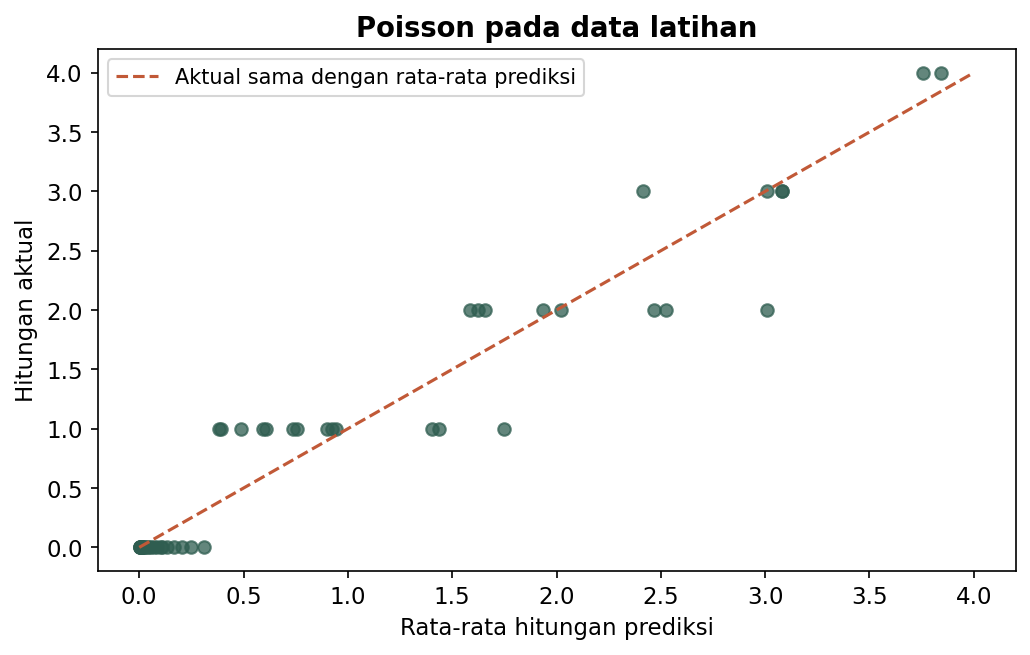

In [13]:
rata_prediksi = model_pois.predict(X_model_pois)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(rata_prediksi, y_model_pois, color="#2F5D50", alpha=0.75)
batas = [0, max(y_model_pois.max(), rata_prediksi.max())]
ax.plot(batas, batas, "--", color="#C15937", label="Aktual sama dengan rata-rata prediksi")
ax.set_xlabel("Rata-rata hitungan prediksi")
ax.set_ylabel("Hitungan aktual")
ax.set_title("Poisson pada data latihan")
ax.legend()
plt.tight_layout()
plt.show()

**Cara membaca:** Prediksi rata-rata tidak harus bulat. Bandingkan penyimpangan terhadap garis dan pemeriksaan overdispersi pada pembahasan.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [14]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model_pois = sm.Poisson(
    y_model_pois,
    sm.add_constant(X_model_pois, has_constant="add").rename(
        columns={"const": "Intercept"}
    ),
).fit(disp=0)

print("Koefisien:")
print(koefisien_model_pois.round(3))
print("\nIRR:")
print(np.exp(koefisien_model_pois).round(3))

overdisp = (uji_model_pois.resid_pearson**2).sum() / uji_model_pois.df_resid
print(f"\nOverdispersi (Pearson chi2 / df): {overdisp:.3f}")

model_nb = smf.negativebinomial(
    "JML_KLAIM ~ USIA + PENGALAMAN + TIPE_MOBIL", data=klaim
).fit(disp=0)
print("AIC Poisson:", round(uji_model_pois.aic, 2))
print("AIC NB     :", round(model_nb.aic, 2))


Koefisien:
USIA          0.023
PENGALAMAN   -0.244
TIPE_MOBIL    0.344
Intercept     0.594
dtype: float64

IRR:
USIA          1.023
PENGALAMAN    0.784
TIPE_MOBIL    1.410
Intercept     1.810
dtype: float64

Overdispersi (Pearson chi2 / df): 0.141
AIC Poisson: 80.86
AIC NB     : 82.86


C:\Users\MyPC PRO\Documents\ekonometrika\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Kesimpulan: tidak ada variabel yang signifikan di data ini (semua
p > 0,3). Overdispersi 0,14 (di bawah 1,5), jadi Poisson cukup, dan AIC
Poisson lebih kecil dari Negative Binomial. Laporkan bahwa data ini
tidak menunjukkan efek yang bisa dibedakan dari nol pada sampel ini.


## Pengayaan: dari peluang gagal bayar ke keputusan kredit (30 sampai 40 menit)

Logit menghasilkan peluang. Keputusan membutuhkan batas risiko atau **ambang**.
Nasabah ditandai berisiko jika peluangnya setidaknya sebesar ambang tersebut.
Apakah ambang 0,5 selalu paling sesuai ketika dua jenis kesalahan memiliki biaya berbeda?

Gunakan 1.000 nasabah dalam data UCI **Taiwan**, bukan Indonesia. Kita memakai
batas kredit dan usia agar contoh singkat. Ini latihan keputusan berdasarkan biaya;
pengembangan model kredit nyata memerlukan informasi pembayaran dan penilaian lain.
Biaya berikut merupakan **asumsi latihan dalam unit biaya**, bukan kerugian bank yang teramati.

<!-- kamus_variabel:kredit_default.csv -->

### Kenali data: Gagal bayar kartu kredit Taiwan

**Data:** `data/kredit_default.csv`. **Satu baris:** satu nasabah dari subset 1.000 pengamatan data UCI Taiwan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `limit_kredit` | Batas kredit yang diberikan kepada nasabah. | Dolar Taiwan (NT$), bukan rupiah | X: penjelas |
| `jenis_kelamin` | Kategori jenis kelamin menurut pencatatan sumber. | 1 = laki-laki; 2 = perempuan | X: penjelas |
| `pendidikan` | Jenjang pendidikan menurut kode sumber. | 1 = pascasarjana; 2 = universitas; 3 = sekolah menengah; 4 = lainnya; kode lain tidak dirinci | X: penjelas |
| `status_nikah` | Status perkawinan menurut kode sumber. | 1 = menikah; 2 = lajang; 3 = lainnya; kode lain tidak dirinci | X: penjelas |
| `usia` | Umur nasabah. | Tahun | X: penjelas |
| `gagal_bayar` | Apakah nasabah mengalami gagal bayar pada periode target. | 1 = gagal bayar; 0 = tidak | Y: target |

Data ini berasal dari Taiwan, bukan Indonesia. Kode kategori tidak otomatis mempunyai jarak numerik yang bermakna; misalnya kode pendidikan 2 bukan dua kali pendidikan kode 1. Pengayaan keputusan kredit hanya memakai limit_kredit dan usia sebagai fitur; kolom kategori tidak diperlakukan sebagai angka berjarak. Biaya kesalahan adalah asumsi latihan dalam unit biaya.

Sumber definisi: [rujukan data](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).


In [15]:
from IPython.display import display

kredit = pd.read_csv(URL_DATA + "kredit_default.csv")
print("Jumlah nasabah:", len(kredit))
print("Jumlah nasabah per kelas:")
print(kredit["gagal_bayar"].value_counts().sort_index())
kredit.head()

Jumlah nasabah: 1000
Jumlah nasabah per kelas:
gagal_bayar
0    780
1    220
Name: count, dtype: int64


,limit_kredit,jenis_kelamin,pendidikan,status_nikah,usia,gagal_bayar
0,340000,2,3,1,47,0
1,240000,2,3,1,41,0
2,200000,1,1,2,32,0
3,200000,1,2,2,58,0
4,240000,1,5,1,50,0


Ada 780 nasabah tidak gagal bayar dan 220 gagal bayar. Menebak semua tidak gagal
bayar sudah benar pada 78% dari keseluruhan tabel, tetapi seluruh gagal bayar terlewat.
Angka ini menjelaskan mengapa kita perlu memeriksa jenis kesalahan dan biayanya.

### 1. Pisahkan latihan, validasi, dan pengujian

Model belajar dari **600 nasabah latihan**. Kita memilih satu dari dua ambang pada
**200 nasabah validasi**. **200 nasabah uji** dipakai setelah ambang ditetapkan.
`stratify` menjaga proporsi kelas; `random_state` membuat pembagian dapat diulangi.

Validasi mengambil 25% dari 800 nasabah yang tersisa, yaitu 200 nasabah.

In [16]:
from sklearn.model_selection import train_test_split

kredit_awal, kredit_uji = train_test_split(
    kredit, test_size=0.2, random_state=42, stratify=kredit["gagal_bayar"]
)
kredit_latih, kredit_validasi = train_test_split(
    kredit_awal, test_size=0.25, random_state=42, stratify=kredit_awal["gagal_bayar"]
)
X_latih_kredit = kredit_latih[["limit_kredit", "usia"]]
y_latih_kredit = kredit_latih["gagal_bayar"]
X_validasi_kredit = kredit_validasi[["limit_kredit", "usia"]]
y_validasi_kredit = kredit_validasi["gagal_bayar"]
print("Latihan:", len(kredit_latih), "Validasi:", len(kredit_validasi), "Uji:", len(kredit_uji))

Latihan: 600 Validasi: 200 Uji: 200


### 2. Latih logit dengan skala yang sebanding

Batas kredit dan usia memiliki skala berbeda. `StandardScaler` mempelajari
rata-rata dan simpangan baku **hanya dari data latihan**. `transform` memakai
patokan yang sama untuk validasi. Jangan mempelajari skala lagi dari validasi atau uji.

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

skala_kredit = StandardScaler()
X_latih_skala_kredit = skala_kredit.fit_transform(X_latih_kredit)
X_validasi_skala_kredit = skala_kredit.transform(X_validasi_kredit)

model_kredit = LogisticRegression(max_iter=1000)
model_kredit.fit(X_latih_skala_kredit, y_latih_kredit)
print("Urutan kelas:", model_kredit.classes_)
peluang_validasi_kredit = model_kredit.predict_proba(X_validasi_skala_kredit)[:, 1]

Urutan kelas: [0 1]


`classes_` menampilkan urutan `[0, 1]`. Karena itu, `[:, 1]` mengambil peluang
kelas 1, yaitu gagal bayar, untuk seluruh baris.

### 3. Bandingkan dua ambang pada data validasi

Asumsi biaya: menandai nasabah lancar sebagai berisiko menghabiskan **1 unit**,
sedangkan meloloskan nasabah yang gagal bayar menghabiskan **5 unit**.
Keputusan benar diberi biaya nol dalam contoh ini.

Matriks kebingungan memakai baris aktual dan kolom prediksi. Posisi `[0, 1]`
menghitung nasabah lancar yang ditandai berisiko; `[1, 0]` menghitung gagal bayar yang terlewat.

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

kelas_validasi_20 = (peluang_validasi_kredit >= 0.20).astype(int)
kelas_validasi_50 = (peluang_validasi_kredit >= 0.50).astype(int)
matriks_validasi_20 = confusion_matrix(y_validasi_kredit, kelas_validasi_20, labels=[0, 1])
matriks_validasi_50 = confusion_matrix(y_validasi_kredit, kelas_validasi_50, labels=[0, 1])
biaya_20 = matriks_validasi_20[0, 1] + 5 * matriks_validasi_20[1, 0]
biaya_50 = matriks_validasi_50[0, 1] + 5 * matriks_validasi_50[1, 0]

biaya_validasi_kredit = pd.DataFrame({"ambang": [0.20, 0.50], "biaya": [biaya_20, biaya_50]})
biaya_validasi_kredit

,ambang,biaya
0,0.2,144
1,0.5,220


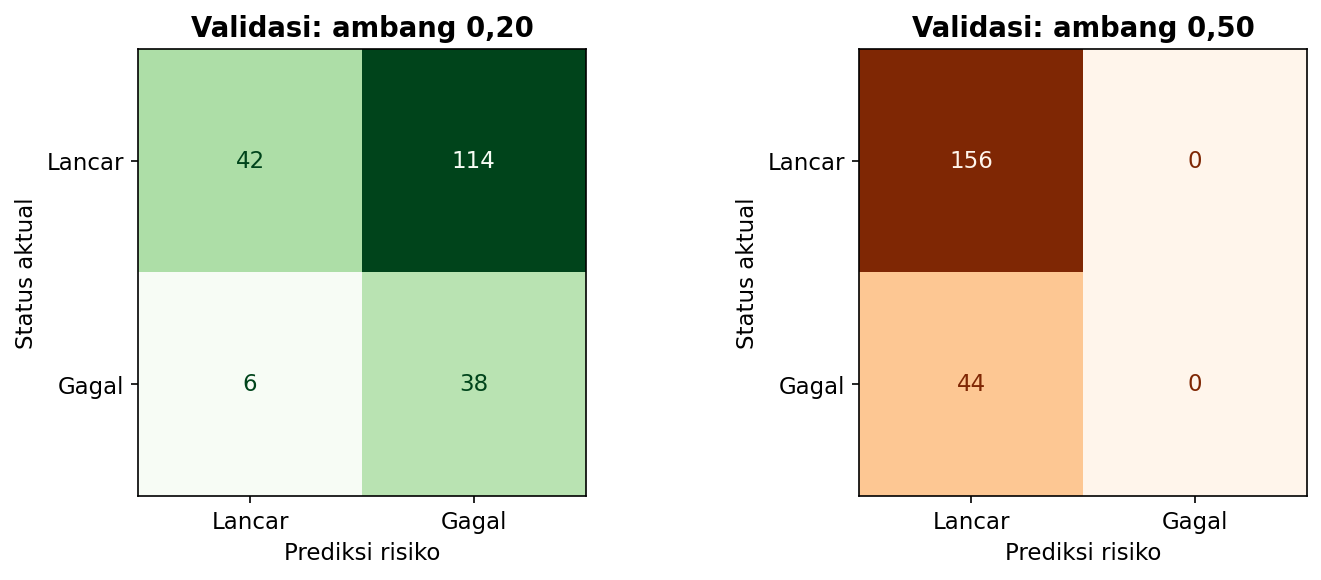

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(matriks_validasi_20, display_labels=["Lancar", "Gagal"]).plot(ax=axes[0], colorbar=False, cmap="Greens")
ConfusionMatrixDisplay(matriks_validasi_50, display_labels=["Lancar", "Gagal"]).plot(ax=axes[1], colorbar=False, cmap="Oranges")
axes[0].grid(False)
axes[1].grid(False)
axes[0].set_title("Validasi: ambang 0,20")
axes[1].set_title("Validasi: ambang 0,50")
axes[0].set_xlabel("Prediksi risiko")
axes[1].set_xlabel("Prediksi risiko")
axes[0].set_ylabel("Status aktual")
axes[1].set_ylabel("Status aktual")
plt.tight_layout()
plt.show()

**Cara membaca:** kanan atas adalah nasabah lancar yang ditandai berisiko.
Kiri bawah adalah gagal bayar yang terlewat. Ambang lebih rendah dapat mengurangi
gagal bayar yang terlewat sambil menambah penolakan nasabah lancar.
Hitung biaya dari dua kotak ini sebelum memilih aturan keputusan.

### 4. Tetapkan ambang, lalu buka data uji

`idxmin` mencari baris dengan biaya validasi terkecil; `loc` mengambil ambangnya.
Kita hanya membandingkan 0,20 dan 0,50, sehingga hasil ini adalah pilihan terbaik
dari **dua pilihan tersebut**, bukan ambang terbaik dari semua kemungkinan.

In [20]:
baris_terbaik_kredit = biaya_validasi_kredit["biaya"].idxmin()
ambang_terpilih_kredit = biaya_validasi_kredit.loc[baris_terbaik_kredit, "ambang"]

X_uji_kredit = kredit_uji[["limit_kredit", "usia"]]
y_uji_kredit = kredit_uji["gagal_bayar"]
X_uji_skala_kredit = skala_kredit.transform(X_uji_kredit)
peluang_uji_kredit = model_kredit.predict_proba(X_uji_skala_kredit)[:, 1]
kelas_uji_kredit = (peluang_uji_kredit >= ambang_terpilih_kredit).astype(int)
matriks_uji_kredit = confusion_matrix(y_uji_kredit, kelas_uji_kredit, labels=[0, 1])
biaya_uji_kredit = matriks_uji_kredit[0, 1] + 5 * matriks_uji_kredit[1, 0]
print("Ambang dipilih pada validasi:", ambang_terpilih_kredit)
print("Matriks pada data uji:")
display(pd.DataFrame(
    matriks_uji_kredit,
    index=["Aktual lancar", "Aktual gagal"],
    columns=["Prediksi lancar", "Prediksi gagal"],
))

Ambang dipilih pada validasi: 0.2
Matriks pada data uji:


,Prediksi lancar,Prediksi gagal
Aktual lancar,54,102
Aktual gagal,6,38


### 5. Bandingkan dengan aturan yang sangat sederhana

Aturan menerima semua melewatkan seluruh gagal bayar. Aturan menolak semua
menolak seluruh nasabah lancar. Kedua aturan ini membantu menilai apakah model
memberi manfaat berdasarkan asumsi biaya yang sama.

Akurasi logit pada uji: 0.46
Bagian gagal bayar yang terdeteksi: 0.864


,aturan,biaya_uji
0,Terima semua,220
1,Tolak semua,156
2,Logit dan ambang validasi,132


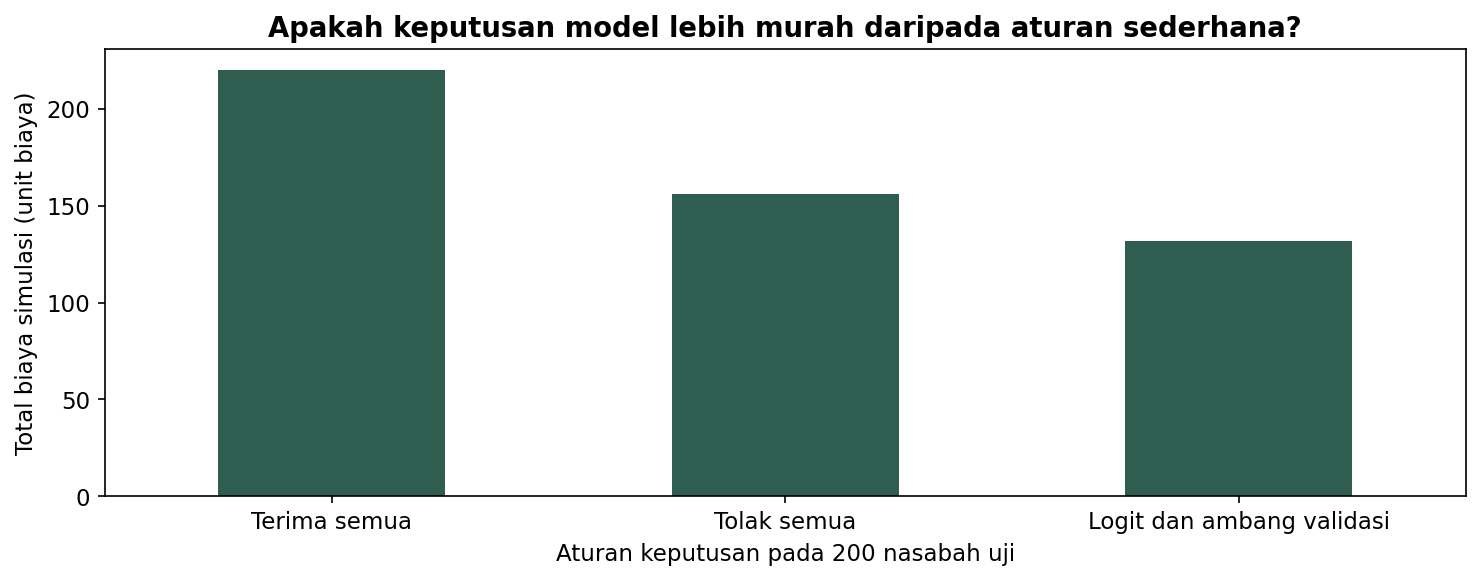

In [21]:
from sklearn.metrics import accuracy_score, recall_score

biaya_terima_semua_kredit = 5 * (y_uji_kredit == 1).sum()
biaya_tolak_semua_kredit = (y_uji_kredit == 0).sum()
hasil_uji_kredit = pd.DataFrame({
    "aturan": ["Terima semua", "Tolak semua", "Logit dan ambang validasi"],
    "biaya_uji": [biaya_terima_semua_kredit, biaya_tolak_semua_kredit, biaya_uji_kredit],
})
print("Akurasi logit pada uji:", round(accuracy_score(y_uji_kredit, kelas_uji_kredit), 3))
print("Bagian gagal bayar yang terdeteksi:", round(recall_score(y_uji_kredit, kelas_uji_kredit), 3))
display(hasil_uji_kredit)

ax = hasil_uji_kredit.plot.bar(x="aturan", y="biaya_uji", legend=False, rot=0, figsize=(10, 4), color="#2F5D50")
ax.set_xlabel("Aturan keputusan pada 200 nasabah uji")
ax.set_ylabel("Total biaya simulasi (unit biaya)")
ax.set_title("Apakah keputusan model lebih murah daripada aturan sederhana?")
plt.tight_layout()
plt.show()

**Cara membaca:** batang lebih rendah berarti biaya kesalahan lebih kecil pada
data uji dan asumsi biaya ini. Model bisa kalah dari aturan sederhana.
Akurasi lebih tinggi juga belum tentu menghasilkan biaya lebih rendah.
Jangan mengganti ambang berdasarkan batang data uji; perubahan rancangan perlu
kembali ke latihan/validasi dan akhirnya diuji pada data baru.

**Hasil pada pembagian ini:** ambang 0,20 dipilih pada validasi. Pada uji,
biaya model 132 unit, terima semua 220 unit, dan tolak semua 156 unit.
Akurasi model 46%, tetapi 38 dari 44 gagal bayar terdeteksi (sekitar 86,4%).
Model mengurangi biaya menurut asumsi latihan meskipun akurasinya lebih rendah.

Hasil contoh dibatasi dua fitur dan sampel 1.000 nasabah. Dalam penilaian kredit
nyata, biaya, peluang yang terkalibrasi, dan kinerja pada nasabah baru perlu diperiksa.
Rujukan: [keputusan berdasarkan biaya, scikit-learn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_cost_sensitive_learning.html)
dan [sumber data UCI](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

### Coba sendiri: jika gagal bayar yang terlewat lebih mahal

Naikkan biaya satu gagal bayar yang terlewat dari 5 menjadi **10 unit**.
Hitung ulang biaya dua ambang dengan matriks **validasi** yang sudah ada.
Bandingkan pilihannya tanpa menggunakan data uji untuk memilih ambang.
Apakah perubahan biaya selalu mengubah ambang yang dipilih?

In [22]:
biaya_validasi_10 = pd.DataFrame({
    "ambang": [0.20, 0.50],
    "biaya": [
        matriks_validasi_20[0, 1] + 10 * matriks_validasi_20[1, 0],
        matriks_validasi_50[0, 1] + 10 * matriks_validasi_50[1, 0],
    ],
})
print(biaya_validasi_10)
print("Ambang pilihan:", biaya_validasi_10.loc[biaya_validasi_10["biaya"].idxmin(), "ambang"])

   ambang  biaya
0     0.2    174
1     0.5    440
Ambang pilihan: 0.2


**Pembahasan:** Biaya tiap ambang berubah sesuai banyaknya gagal bayar yang terlewat. Ambang pilihan dapat tetap sama jika ambang itu sudah lebih murah; menaikkan biaya tidak menjamin pilihan berpindah. Penetapan ambang tetap berdasarkan validasi.